<a href="https://colab.research.google.com/github/ethereal-arko/Mall_Customer_Segmentation/blob/main/Mall_Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Project Introduction

### Mall Customer Segmentation using K-Means Clustering

**Objective:** To group mall customers into distinct segments based on their annual income and spending score using the K-Means clustering algorithm.

**Machine Learning Type:** Unsupervised Learning

**Algorithm:** K-Means Clustering

**Selected Features:**
- Annual Income (k$)
- Spending Score (1–100)

Customer segmentation can help businesses understand different customer behaviors and develop more effective marketing strategies.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Load the dataset
customer_data = pd.read_csv('/content/Mall_Customers.csv')

# Display the first five rows
display(customer_data.head())

# Check dataset dimensions
print("Dataset shape:", customer_data.shape)

# Check column names, data types, and non-null counts
customer_data.info()

# Check missing values
print("\nMissing values per column:")
print(customer_data.isnull().sum())


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


## 2. Feature Selection

The dataset contains five columns: CustomerID, Gender, Age, Annual Income, and Spending Score.

For this project, we select **Annual Income (k$)** and **Spending Score (1-100)** as the input features.

- **Annual Income:** Represents the customer's annual income in thousands of dollars.
- **Spending Score:** Represents the customer's spending behavior on a scale from 1 to 100.

CustomerID is excluded because it is only an identifier. Gender and Age are also excluded to keep the analysis focused on income and spending behavior.

The selected features will be used to group customers into clusters using the K-Means algorithm.

In [10]:


# Load dataset directly from GitHub
dataset_url = "https://raw.githubusercontent.com/ethereal-arko/Mall_Customer_Segmentation/main/Mall_Customers.csv"

customer_data = pd.read_csv(dataset_url)

# Verify successful loading
print("Dataset loaded successfully!")
print("Dataset shape:", customer_data.shape)
display(customer_data.head())


Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the distribution and relationships within a dataset before applying a machine learning algorithm.

In this project, we visualize Annual Income against Spending Score using a scatter plot. Each point represents one customer.

This visualization helps us identify possible customer groups and understand whether the data contains visible patterns that may be discovered by K-Means clustering.

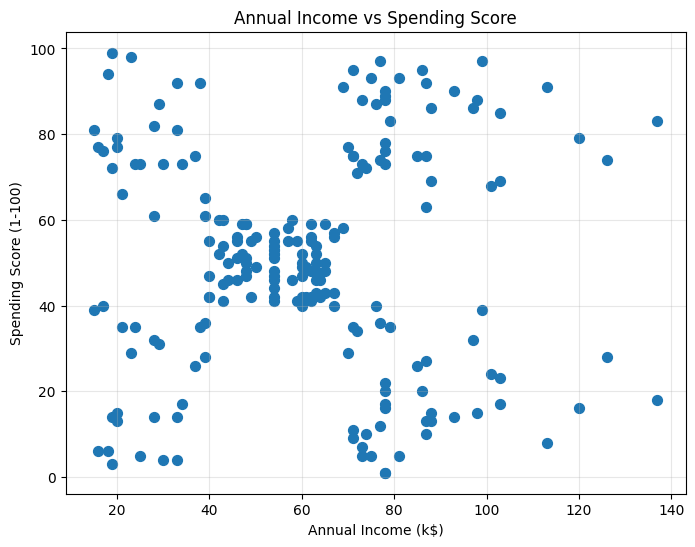

In [3]:

# Visualize Annual Income vs Spending Score
plt.figure(figsize=(8, 6))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    s=50
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(alpha=0.3)
plt.show()


## 4. Optimal Number of Clusters: Elbow Method

The Elbow Method is used to estimate a suitable number of clusters for K-Means clustering.

For each value of K, the algorithm calculates the Within-Cluster Sum of Squares (WCSS), also known as inertia. WCSS measures the sum of squared distances between data points and their assigned cluster centroids.

As K increases, WCSS generally decreases. We plot WCSS against K and look for an elbow point, where the rate of decrease becomes noticeably smaller.

The elbow point provides a reasonable estimate of the number of clusters, although it does not always identify a uniquely optimal value.

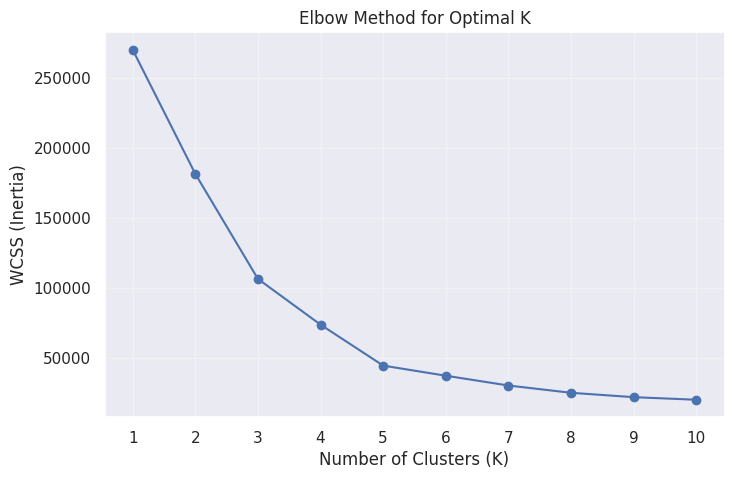

K = 1: WCSS = 269981.28
K = 2: WCSS = 181363.60
K = 3: WCSS = 106348.37
K = 4: WCSS = 73679.79
K = 5: WCSS = 44448.46
K = 6: WCSS = 37233.81
K = 7: WCSS = 30241.34
K = 8: WCSS = 25036.42
K = 9: WCSS = 21916.79
K = 10: WCSS = 20072.07


In [4]:

# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
sns.set_theme()

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

# Display the WCSS values
for k, value in enumerate(wcss, start=1):
    print(f"K = {k}: WCSS = {value:.2f}")


## 5. Training the K-Means Clustering Model

Based on the Elbow Method, we select **K = 5** as a reasonable number of clusters.

K-Means partitions the customers into five groups by assigning each customer to the nearest cluster centroid and iteratively updating the centroids to reduce the within-cluster sum of squares.

The `fit_predict()` method trains the model on the selected features and returns a cluster label for each customer.

**Note:** Cluster labels are numeric identifiers, not rankings. For example, Cluster 0 is not necessarily better or worse than Cluster 1.

In [5]:

# Train the K-Means model with 5 clusters
kmeans = KMeans(
    n_clusters=5,
    init='k-means++',
    random_state=42,
    n_init=10
)

# Fit the model and assign a cluster label to each customer
Y = kmeans.fit_predict(X)

# Display the first 20 cluster labels
print("First 20 cluster labels:")
print(Y[:20])

# Count customers in each cluster
print("\nNumber of customers in each cluster:")
print(pd.Series(Y).value_counts().sort_index())


First 20 cluster labels:
[4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2]

Number of customers in each cluster:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


## 6. Visualization of Customer Segments

After training the K-Means model, we visualize the five clusters using a scatter plot.

Each point represents a customer, and its color indicates the assigned cluster. The cluster centroids represent the mean Annual Income and Spending Score of the customers assigned to each cluster.

This visualization helps us understand how the model groups customers according to their income and spending behavior.

**Note:** Cluster colors and numeric labels are arbitrary identifiers and do not indicate an inherent ranking.

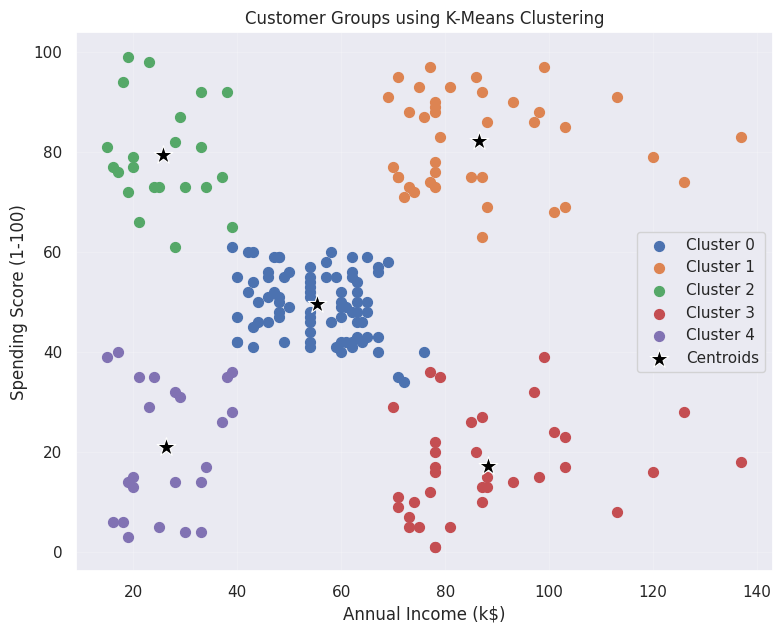

In [6]:

# Convert the selected features to a NumPy array
X_array = X.to_numpy()

# Convert cluster labels to a NumPy array
Y_array = np.asarray(Y)

# Plot the five customer clusters
plt.figure(figsize=(9, 7))

for cluster_id in range(5):
    plt.scatter(
        X_array[Y_array == cluster_id, 0],
        X_array[Y_array == cluster_id, 1],
        s=50,
        label=f'Cluster {cluster_id}'
    )

# Plot the cluster centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    marker='*',
    c='black',
    edgecolor='white',
    linewidth=0.8,
    label='Centroids'
)

plt.title('Customer Groups using K-Means Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## 7. Cluster Analysis and Customer Segment Interpretation

After clustering, we analyze the characteristics of each group using the mean Annual Income and mean Spending Score.

For each cluster, we calculate:
- **Customer Count:** Number of customers assigned to the cluster.
- **Average Annual Income:** Mean annual income of the cluster.
- **Average Spending Score:** Mean spending score of the cluster.

These statistics help interpret the clusters in business terms, such as high-income customers with high spending scores or low-income customers with low spending scores.

The interpretation is based on the observed cluster characteristics; the cluster labels themselves do not have predefined meanings.

In [7]:

# Create a copy of the selected features
cluster_data = X.copy()

# Add the cluster label for each customer
cluster_data['Cluster'] = Y

# Calculate cluster statistics
cluster_summary = cluster_data.groupby('Cluster').agg(
    Customer_Count=('Annual Income (k$)', 'size'),
    Average_Annual_Income=('Annual Income (k$)', 'mean'),
    Average_Spending_Score=('Spending Score (1-100)', 'mean')
).round(2)

# Display the summary
display(cluster_summary)


,Customer_Count,Average_Annual_Income,Average_Spending_Score
Cluster,,,
0,81,55.30,49.52
1,39,86.54,82.13
2,22,25.73,79.36
3,35,88.20,17.11
4,23,26.30,20.91


## 8. Evaluating Clustering Quality Using Silhouette Score

The Silhouette Score evaluates how well data points fit within their assigned clusters compared with neighboring clusters.

The score ranges from -1 to +1:
- A score close to +1 indicates that points are well separated from neighboring clusters.
- A score around 0 indicates overlapping clusters or points near cluster boundaries.
- A negative score may indicate that some points are assigned to an unsuitable cluster.

Unlike classification accuracy, the Silhouette Score does not require predefined ground-truth labels. It provides an internal measure of clustering quality.

In [8]:

# Calculate the Silhouette Score
sil_score = silhouette_score(X, Y)

print(f"Silhouette Score (K=5): {sil_score:.4f}")


Silhouette Score (K=5): 0.5539


## 9. Conclusion

In this project, the K-Means clustering algorithm was applied to segment 200 mall customers based on Annual Income and Spending Score.

The Elbow Method was used to select five clusters as a reasonable choice. The trained model grouped the customers into five segments with different income and spending characteristics.

The cluster analysis identified the following groups:

1. Average-income, average-spending customers
2. High-income, high-spending customers
3. Low-income, high-spending customers
4. High-income, low-spending customers
5. Low-income, low-spending customers

The model achieved a Silhouette Score of **0.5539** for K = 5, suggesting reasonably separated clusters in the selected feature space.

These segments can help businesses explore targeted marketing strategies, personalized offers, customer retention, and product recommendations.

### Limitations

- Only Annual Income and Spending Score were used; Age and Gender were not included.
- The choice of five clusters was based primarily on the Elbow Method.
- Cluster assignments depend on the selected features, scaling choices, and model initialization.
- The results describe patterns in this dataset and should not be treated as proof of future customer behavior.

### Future Improvements

- Compare Silhouette Scores for different values of K.
- Explore feature scaling and compare the resulting cluster structures.
- Analyze Age and Gender separately to understand additional customer patterns.
- Validate whether the resulting segments are useful for actual marketing decisions.

In [9]:

print("PROJECT SUMMARY")
print("-" * 40)

print("Total customers:", len(X))
print("Number of features:", X.shape[1])
print("Number of clusters:", kmeans.n_clusters)
print("Silhouette Score:", round(sil_score, 4))

print("\nCustomers per cluster:")
print(pd.Series(Y).value_counts().sort_index())

print("\nCluster summary:")
display(cluster_summary)


PROJECT SUMMARY
----------------------------------------
Total customers: 200
Number of features: 2
Number of clusters: 5
Silhouette Score: 0.5539

Customers per cluster:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster summary:


,Customer_Count,Average_Annual_Income,Average_Spending_Score
Cluster,,,
0,81,55.30,49.52
1,39,86.54,82.13
2,22,25.73,79.36
3,35,88.20,17.11
4,23,26.30,20.91
